In [1]:
! pip install -q optuna
! pip install -q emoji

In [2]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
import optuna
import ast
import re
import emoji
from transformers.utils import logging as hf_logging
import gc
import shutil
import random
import math
import html
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification, EarlyStoppingCallback, TrainerCallback
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, classification_report
    

In [3]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/thesis-full/thesis_full.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27833 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   text_id                        27833 non-null  object
 1   annotators_id                  27833 non-null  object
 2   text                           27832 non-null  object
 3   topic                          27833 non-null  object
 4   is_noise_or_spam_text          27833 non-null  object
 5   toxicity                       27833 non-null  object
 6   polarized                      27833 non-null  object
 7   profanity_obscenity            27833 non-null  object
 8   threat_incitement_to_violence  27833 non-null  object
 9   insults                        27833 non-null  object
 10  identity_attack                27833 non-null  object
 11  sexually_explicit              27833 non-null  object
 12  key                            27833 non-null  object
 13  c

In [5]:
df_main = df.copy()

In [6]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df_main[col] = df_main[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [7]:
df_main.iloc[5389]

text_id                                                                     1-6084
annotators_id                                                    ['20', '5', '33']
text                             Sosialisasi dan Edukasi Pasar Modal Terpadu Ha...
topic                                                                        Syiah
is_noise_or_spam_text                                                  ([0, 1], 0)
toxicity                                                                 [0, 0, 0]
polarized                                                                [0, 0, 0]
profanity_obscenity                                                      [0, 0, 0]
threat_incitement_to_violence                                            [0, 0, 0]
insults                                                                  [0, 0, 0]
identity_attack                                                          [0, 0, 0]
sexually_explicit                                                        [0, 0, 0]
key 

In [8]:
df_main['is_noise_or_spam_text'].iloc[5389] = [0, 1, 0]

/tmp/ipykernel_49/1462503684.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_main['is_noise_or_spam_text'].iloc[5389] = [0, 1, 0]


In [9]:
for col in cols:
    for idx, x in df_main[col].items():
        try:
            for i in x:
                int(i)
        except Exception as e:
            print(f"Column: {col}")
            print(f"Row: {idx}")
            print("Cell:", x)
            print("Cell type:", type(x))
            print("Element types:", [type(i) for i in x])
            raise

In [10]:
print(cols)
cols2 = cols
cols2.remove('polarized')
print(cols2)

['is_noise_or_spam_text', 'toxicity', 'polarized', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']
['is_noise_or_spam_text', 'toxicity', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']


In [11]:
def majority_vote(x):
    x = [int(i) for i in x]
    return round(sum(x)/len(x))

for col in cols2:
    df_main[col] = df_main[col].apply(majority_vote)

In [12]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]
df_main = df_main.dropna()
df_main.isnull().sum()

text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
key                              0
cleaned_text                     0
processed_text                   0
dtype: int64

In [13]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26375 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   text_id                        26375 non-null  object
 1   annotators_id                  26375 non-null  object
 2   text                           26375 non-null  object
 3   topic                          26375 non-null  object
 4   is_noise_or_spam_text          26375 non-null  int64 
 5   toxicity                       26375 non-null  int64 
 6   polarized                      26375 non-null  object
 7   profanity_obscenity            26375 non-null  int64 
 8   threat_incitement_to_violence  26375 non-null  int64 
 9   insults                        26375 non-null  int64 
 10  identity_attack                26375 non-null  int64 
 11  sexually_explicit              26375 non-null  int64 
 12  key                            26375 non-null  object
 13  cleane

# Polarization as Feature

In [14]:
x = df_main["polarized"].iloc[0]
print(type(x), repr(x))

<class 'list'> ['0', '0']


In [15]:
df_main["polarization_list"] = df_main["polarized"].apply(lambda xs: [int(v) for v in xs])
df_main["pol_avg"] = df_main["polarization_list"].apply(lambda xs: float(np.mean(xs)))

print(df_main[["polarized", "pol_avg"]].head())

   polarized   pol_avg
0     [0, 0]  0.000000
1     [1, 1]  1.000000
2  [0, 0, 0]  0.000000
3  [1, 0, 0]  0.333333
4     [1, 1]  1.000000


# Cleaning

In [16]:
SOURCE_COL = "cleaned_text"

for c in [SOURCE_COL]:
    if c in df.columns:
        n = df[c].fillna("").astype(str).map(emoji.emoji_count).gt(0).sum()
        print(f"{c:13s}: {n if n > 0 else 'None'}")

cleaned_text : 5083


In [17]:
EMOJI_LANG = "id"

In [18]:
# Emoticon teks -> kata. Hanya dicocokkan kalau berdiri sendiri (diapit spasi),
# supaya tidak salah tangkap di tengah kata.
emoticon_dict = {
    ":)": "senyum", ":-)": "senyum", "(:": "senyum", ":]": "senyum", "=)": "senyum",
    ":d": "tertawa", ":-d": "tertawa", "xd": "tertawa", "wkwk": "tertawa",
    ":(": "sedih", ":-(": "sedih", "):": "sedih", ":'(": "menangis",
    ";)": "berkedip", ";-)": "berkedip",
    ":p": "menjulurkan lidah", ":-p": "menjulurkan lidah",
    ":o": "terkejut", ":-o": "terkejut",
    ":/": "ragu", ":-/": "ragu",
    ">:(": "marah", "-_-": "kesal", "<3": "cinta", "</3": "patah hati",
}
_emoticon_re = re.compile(
    r"(?<!\S)(" + "|".join(re.escape(k) for k in sorted(emoticon_dict, key=len, reverse=True)) + r")(?!\S)",
    flags=re.IGNORECASE,
)


def convert_emoticons(text):
    return _emoticon_re.sub(lambda m: f" {emoticon_dict[m.group(1).lower()]} ", text)


def convert_emojis(text, language=EMOJI_LANG):
    # 😂 -> "wajah gembira berurai air mata"
    text = emoji.demojize(text, delimiters=("<<", ">>"), language=language)
    return re.sub(r"<<([^<>]+)>>", lambda m: " " + m.group(1).replace("_", " ") + " ", text)


def normalize_slang(text):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])


def preprocess_text(text, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. decode HTML entities (&amp; -> &) dan hapus tag HTML
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)

    # 2. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 3. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 4. emoticon -> kata (setelah URL dibuang, supaya "http://" tidak terbaca ":/")
    text = convert_emoticons(text)

    # 5. emoji -> kata (HARUS sebelum langkah 7, karena langkah 7 menghapus simbol/emoji)
    text = convert_emojis(text)

    # 6. remove numbers
    text = re.sub(r'\d+', '', text)

    # 7. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', ' ', text)

    # 9. normalize repeated chars (contoh: anjiiing -> anjiing, !!!!! -> !!)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 10. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 11. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Contoh
for s in ["I hate you 🤬🔥 @user123 https://t.co/abc :(",
          "i don't care😂😂 #stupid",
          "awesome <3"]:
    print("SEBELUM:", s)
    print("SESUDAH:", preprocess_text(s), "\n")

SEBELUM: I hate you 🤬🔥 @user123 https://t.co/abc :(
SESUDAH: i hate you wajah dengan simbol pada mulut api sedih 

SEBELUM: i don't care😂😂 #stupid
SESUDAH: i don t care wajah gembira berurai air mata wajah gembira berurai air mata stupid 

SEBELUM: awesome <3
SESUDAH: awesome cinta 



In [20]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main[SOURCE_COL]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x)
    )
)

pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(10, random_state=42)

100%|██████████| 26375/26375 [00:06<00:00, 3844.36it/s]


,cleaned_text,processed_text
1284,"Pelepasan Tim Nasional Bola Voli Putra dan Voli Pantai Asian Games XIX/2023 Hangzhou, China.","pelepasan tim nasional bola voli putra dan voli pantai asian games xix hangzhou, china."
19418,Ini hoax ya! #Rempang TKA China,ini hoax ya! rempang tka china
449,"Kementerian Hukum dan HAM (Kemenkumham) buka lowongan untuk lulusan SMA dan SMK untuk tes CPNS 2023, minat? Ini link daftarnya","kementerian hukum dan ham kemenkumham buka lowongan untuk lulusan sma dan smk untuk tes cpns , minat? ini link daftarnya"
15848,"Serangan udara penjajah zionis Israel tanpa henti membom beberapa lokasi di Gaza, Palestina sekarang. 25-10-2023 #GazaGenocides","serangan udara penjajah zionis israel tanpa henti membom beberapa lokasi di gaza, palestina sekarang. gazagenocides"
21535,#Palestina vs #Israel: Bentrokan terus berlanjut antara tentara pendudukan dan pejuang perlawanan Palestina di markas polisi Zionis di Sderot.,palestina vs israel bentrokan terus berlanjut antara tentara pendudukan dan pejuang perlawanan palestina di markas polisi zionis di sderot.
27361,"Pengungsi Rohingya di Malaysia demo, minta tanah.","pengungsi rohingya di malaysia demo, minta tanah."
2481,"IDN Times World News: Pemimpin Hamas sebut kesepakatan gencatan senjata makin dekat. Pemimpin Hamas, Ismail Haniyeh, menegaskan bahwa kesepakatan ...","idn times world news pemimpin hamas sebut kesepakatan gencatan senjata makin dekat. pemimpin hamas, ismail haniyeh, menegaskan bahwa kesepakatan g..."
7128,"Gila, Jakarta jam segini masih ramai saja, ya ternyata.","gila, jakarta jam segini masih ramai saja, ya ternyata."
22025,Pertahanan sipil di Gaza diserang teroris Israel #Palestine #savegazafromzionists #Gaza #FreePalestine,pertahanan sipil di gaza diserang teroris israel palestine savegazafromzionists gaza freepalestine
21314,"Yaas lagi lihat drama pemilu. Gila sih, gue bukan pendukung JKW, tetapi pas flashback apa yang dia alami, memang nggak tahu diri juga itu emaknya,...","yaas lagi lihat drama pemilu. gila sih, gue bukan pendukung jkw, tetapi pas flashback apa yang dia alami, memang nggak tahu diri juga itu emaknya,..."


In [40]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26375 entries, 0 to 27832
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   text_id                        26375 non-null  object 
 1   annotators_id                  26375 non-null  object 
 2   text                           26375 non-null  object 
 3   topic                          26375 non-null  object 
 4   is_noise_or_spam_text          26375 non-null  int64  
 5   toxicity                       26375 non-null  int64  
 6   polarized                      26375 non-null  object 
 7   profanity_obscenity            26375 non-null  int64  
 8   threat_incitement_to_violence  26375 non-null  int64  
 9   insults                        26375 non-null  int64  
 10  identity_attack                26375 non-null  int64  
 11  sexually_explicit              26375 non-null  int64  
 12  key                            26375 non-null  obje

In [21]:
df_main['toxicity'].value_counts()

toxicity
0    23976
1     2399
Name: count, dtype: int64

# Balancing

In [22]:
pos = df_main[df_main["toxicity"] == 1]
neg = df_main[df_main["toxicity"] == 0].sample(n=3 * len(pos), random_state=42)
df_final = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)

In [23]:
df_final['toxicity'].value_counts()

toxicity
0    7197
1    2399
Name: count, dtype: int64

# Baseline NusaBert

5 epoch, 8 batch, 1e-5e LR, 0.01 weight decay

In [25]:
x = df_final[["processed_text", "pol_avg"]]
y = df_final['toxicity']

In [26]:
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

Stage 1 split sizes: {'train': 6716, 'val': 960, 'test': 1920}


In [27]:
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 class weights (class 0, class 1): tensor([0.6667, 2.0000])


In [28]:
def make_df(x, y):
    df = x.copy()
    df["label"] = y.values
    return df.reset_index(drop=True)

train_df = make_df(x_train, y_train)
val_df = make_df(x_val, y_val)
test_df = make_df(x_test, y_test)

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 6716
    })
    validation: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 960
    })
    test: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 1920
    })
})


In [29]:
tokenizer = AutoTokenizer.from_pretrained("LazarusNLP/NusaBERT-large")

config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/261k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/984k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/28.9k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

In [30]:
def tokenize_with_feature(batch):
    prefix = [f"Nilai rata-rata polarisasi: {v:.2f}" for v in batch["pol_avg"]]
    return tokenizer(prefix, batch["processed_text"], truncation="only_second", max_length=128, padding='max_length')

tokenized = dataset.map(tokenize_with_feature, batched=True)
tokenized = tokenized.remove_columns(["processed_text", "pol_avg"])

print(tokenizer.decode(tokenized["train"][0]["input_ids"]))

Map:   0%|          | 0/6716 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/1920 [00:00<?, ? examples/s]

[CLS] nilai rata - rata polarisasi : 0. 00 [SEP] klasemen akhir asian games hangzhou indonesia finis posisi, china rekor medal i emas. wanita mengangkat beban cabang olahr aga peraih medal i untuk indonesia medal i emas atlet peraih emas medal i perak atlet peraih perak medal i perunggu atlet peraih perunggu selengkapnya [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [31]:
tokenized_datasets_1 = dataset.map(tokenize_with_feature, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text",'pol_avg'])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

Map:   0%|          | 0/6716 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/1920 [00:00<?, ? examples/s]

In [32]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }

In [33]:
model_s1 = AutoModelForSequenceClassification.from_pretrained(
    "LazarusNLP/NusaBERT-large", num_labels=2)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.35GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: LazarusNLP/NusaBERT-large
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [34]:
print(model_s1.config.num_labels, model_s1.config.id2label)
print(model_s1.classifier.weight.shape) 

2 {0: 'LABEL_0', 1: 'LABEL_1'}
torch.Size([2, 1024])


In [35]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [36]:
args_s1 = TrainingArguments(
    output_dir="./model_toxicity",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True
)


trainer_s1 = WeightedTrainerSingleLabel(
    model=model_s1,
    args=args_s1,
    train_dataset=train_dataset_1,
    eval_dataset=val_dataset_1,
    compute_metrics=compute_metrics_s1,
    class_weights=class_weights_s1,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer_s1.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.166636,0.443742,0.779167,0.535000,0.891667,0.668750,0.751562,0.890856,0.726610
2,0.237286,0.390042,0.819792,0.602446,0.820833,0.694885,0.783511,0.909167,0.773896
3,0.250427,0.509147,0.853125,0.680000,0.779167,0.726214,0.812929,0.910214,0.767728
4,0.032057,0.607965,0.852083,0.678832,0.775000,0.723735,0.811370,0.903293,0.723726


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1680, training_loss=0.35594864940087845, metrics={'train_runtime': 1633.3529, 'train_samples_per_second': 20.559, 'train_steps_per_second': 1.286, 'total_flos': 6258851036110848.0, 'train_loss': 0.35594864940087845, 'epoch': 4.0})

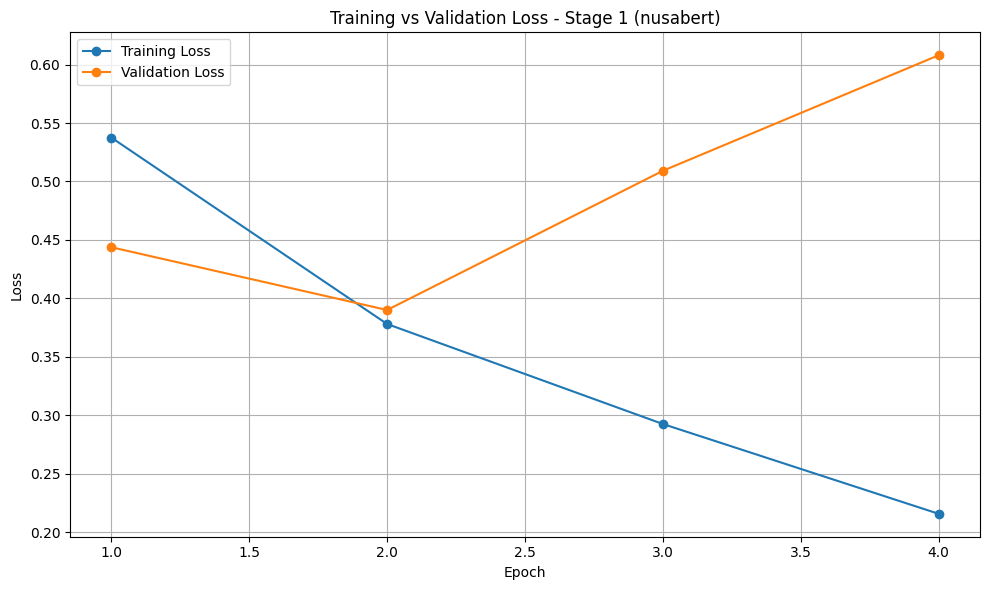

In [37]:
import matplotlib.pyplot as plt

history_s1 = trainer_s1.state.log_history

# Training loss rata-rata per epoch
train_logs_s1 = [x for x in history_s1 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

epoch_numbers_s1 = sorted(set(int(np.ceil(e)) for e in train_epochs_s1))
avg_train_loss_s1 = [
    np.mean([l for e, l in zip(train_epochs_s1, train_losses_s1) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s1
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s1 = {}
for x in history_s1:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s1:
            val_loss_by_epoch_s1[ep] = x['eval_loss']
val_epochs_s1 = sorted(val_loss_by_epoch_s1)
val_losses_s1 = [val_loss_by_epoch_s1[ep] for ep in val_epochs_s1]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()
# pred_label1_tuned = (probs1_test >= best_threshold_s1).astype(int)

print("Stage 1 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y_test, pred_label1))

# print(f"\nStage 1 classification report @ tuned threshold ({best_threshold_s1:.4f}) -- test set:")
# print(classification_report(y_test, pred_label1_tuned))

Stage 1 classification report @ default threshold (0.5) -- test set:
              precision    recall  f1-score   support

           0       0.93      0.84      0.88      1440
           1       0.63      0.82      0.71       480

    accuracy                           0.83      1920
   macro avg       0.78      0.83      0.80      1920
weighted avg       0.86      0.83      0.84      1920



In [39]:
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}\n")


ROC-AUC (test): 0.9042
PR-AUC  (test): 0.7575

